# Can Speculative Crowding Improve Commodity ETF Momentum?

Kang, Rouwenhorst and Tang (2021) show that commodity momentum earns most of its premium when speculators are not already crowded into the trade. We adapt their analysis to 12 commodity ETFs.

**Contribution.** (i) The paper's futures prices are commercial data: we use investable ETFs, which can be downloaded in the notebook. (ii) Our sample includes 2020-2026, after the end of the paper's sample. (iii) The paper dates CFTC positions on the Tuesday they are measured, but they are only published on the Friday: we show what happens when only published positions are used.

**Main results.** With the paper's timing, the low-crowding strategy has a Sharpe ratio of 0.38, against 0.25 for classical momentum, a gap well below the uncertainty on a Sharpe ratio over 11 years. This timing cannot be executed, because CFTC positions are only published on the Friday. Using only published positions, the Sharpe ratio of the low-crowding strategy falls to 0.25, the same as classical momentum.

**References.** Kang, Rouwenhorst and Tang (2021), *Crowding and Factor Returns*, SSRN 3814952. Code: the course package [`skfin`](https://github.com/schampon/skfin) (backtesting, metrics, plots and data loading). Data: [CFTC Commitments of Traders](https://publicreporting.cftc.gov/Commitments-of-Traders/Legacy-Futures-Only/6dca-aqww) and Yahoo Finance.

In [3]:
pip install numpy.lib.array_utils

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement numpy.lib.array_utils (from versions: none)
ERROR: No matching distribution found for numpy.lib.array_utils


In [5]:
from urllib.parse import urlencode

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from skfin.backtesting import compute_pnl
from skfin.backtesting_with_cost import average_holding_period
from skfin.dataloaders.cache import CacheManager
from skfin.dataloaders.web_utils import WebUtils
from skfin.datasets import load_yf_returns
from skfin.metrics import drawdown, sharpe_ratio
from skfin.plot import line

START, END = "2010-01-01", "2026-11-01"
CACHE = "data"
N_LEG = 6

# ETF ticker -> CFTC code of the corresponding futures market
MARKETS = {
    "USO": "067651",  # WTI crude oil
    "UNG": "023651",  # natural gas
    "UGA": "111659",  # RBOB gasoline
    "CPER": "085692",  # copper
    "CORN": "002602",  # corn
    "WEAT": "001602",  # wheat
    "SOYB": "005602",  # soybeans
    "CANE": "080732",  # sugar
    "GLD": "088691",  # gold
    "SLV": "084691",  # silver
    "PPLT": "076651",  # platinum
    "PALL": "075651",  # palladium
}

sr = lambda x: sharpe_ratio(x, 52, remove_zeros=False)

## 1. Data

**Returns.** The paper uses nearby futures prices from Commodity Systems Inc., which are not free. We use ETFs instead. Eight hold futures and roll them (USO, UNG, UGA, CPER, CORN, WEAT, SOYB, CANE); four hold the metal (GLD, SLV, PPLT, PALL). ETF returns therefore approximate rolled futures returns, net of fees and with each fund's own roll schedule. We use adjusted prices and compound daily returns from Tuesday to Tuesday to obtain the weekly return of ETF $i$:

$$
r_{i,t} = \prod_{d \in \text{week } t} \left(1 + r^{day}_{i,d}\right) - 1.
$$


**Positions.** The CFTC Legacy, futures-only report gives, each week, the long and short positions of non-commercial traders and the open interest $OI_{i,t}$ of each market. Following equations (2)-(4) of the paper, speculative pressure and crowding are:

$$
Q_{i,t} = \frac{Long_{i,t} - Short_{i,t}}{OI_{i,t}},
\qquad
C_{i,t} = Q_{i,t} - \frac{1}{52}\sum_{k=1}^{52} Q_{i,t-k}.
$$

In [6]:
daily = load_yf_returns(list(MARKETS), start=START, end=END, cache_dir=CACHE)["price_returns"]
ret = daily.add(1).resample("W-TUE").prod(min_count=1).sub(1).loc[:END, list(MARKETS)]


def load_crowding(dataset="6dca-aqww"):
    def download():
        query = {
            "$select": "report_date_as_yyyy_mm_dd as report, cftc_contract_market_code as code, "
            "open_interest_all as oi, noncomm_positions_long_all as l, noncomm_positions_short_all as s",
            "$where": f"cftc_contract_market_code in {tuple(MARKETS.values())} "
            f"and report_date_as_yyyy_mm_dd between '{START}' and '{END}'",
            "$limit": 100000,
        }
        url = f"https://publicreporting.cftc.gov/resource/{dataset}.json?{urlencode(query)}"
        return pd.DataFrame(WebUtils.get_response(url).json())

    raw = CacheManager(CACHE).get_cached_dataframe(f"cot_{dataset}.parquet", download)
    raw = raw.astype({"oi": float, "l": float, "s": float}).assign(report=lambda x: pd.to_datetime(x["report"]))
    q = raw.assign(q=(raw["l"] - raw["s"]) / raw["oi"]).pivot(index="report", columns="code", values="q")
    q = q.rename(columns={v: k for k, v in MARKETS.items()})[list(MARKETS)]
    return q - q.shift(1).rolling(52).mean()


crowding = load_crowding()
pd.DataFrame(
    {
        "first return": ret.apply(lambda x: x.first_valid_index().date()),
        "return (%/yr)": ret.mean() * 5200,
        "vol (%/yr)": ret.std() * np.sqrt(52) * 100,
        "crowding mean": crowding.mean(),
        "crowding std": crowding.std(),
    }
).round(2)

,first return,return (%/yr),vol (%/yr),crowding mean,crowding std
USO,2010-01-05,3.07,36.95,-0.00,0.04
UNG,2010-01-05,-17.97,47.57,0.00,0.05
UGA,2010-01-05,14.25,35.08,-0.00,0.04
CPER,2011-11-22,5.57,22.07,0.00,0.10
CORN,2010-06-15,-0.15,20.42,-0.00,0.11
WEAT,2011-09-20,-8.05,25.35,-0.00,0.08
SOYB,2011-09-20,1.87,16.91,-0.00,0.11
CANE,2011-09-20,-2.64,22.34,-0.01,0.10
GLD,2010-01-05,8.56,16.22,0.00,0.11
SLV,2010-01-05,11.18,31.39,-0.00,0.10


Returns differ widely across funds: UNG loses about 18% a year while UGA gains about 14%. Crowding is centred on zero by construction, with a standard deviation ranging from 0.04 (USO, UGA) to 0.16 (PALL).

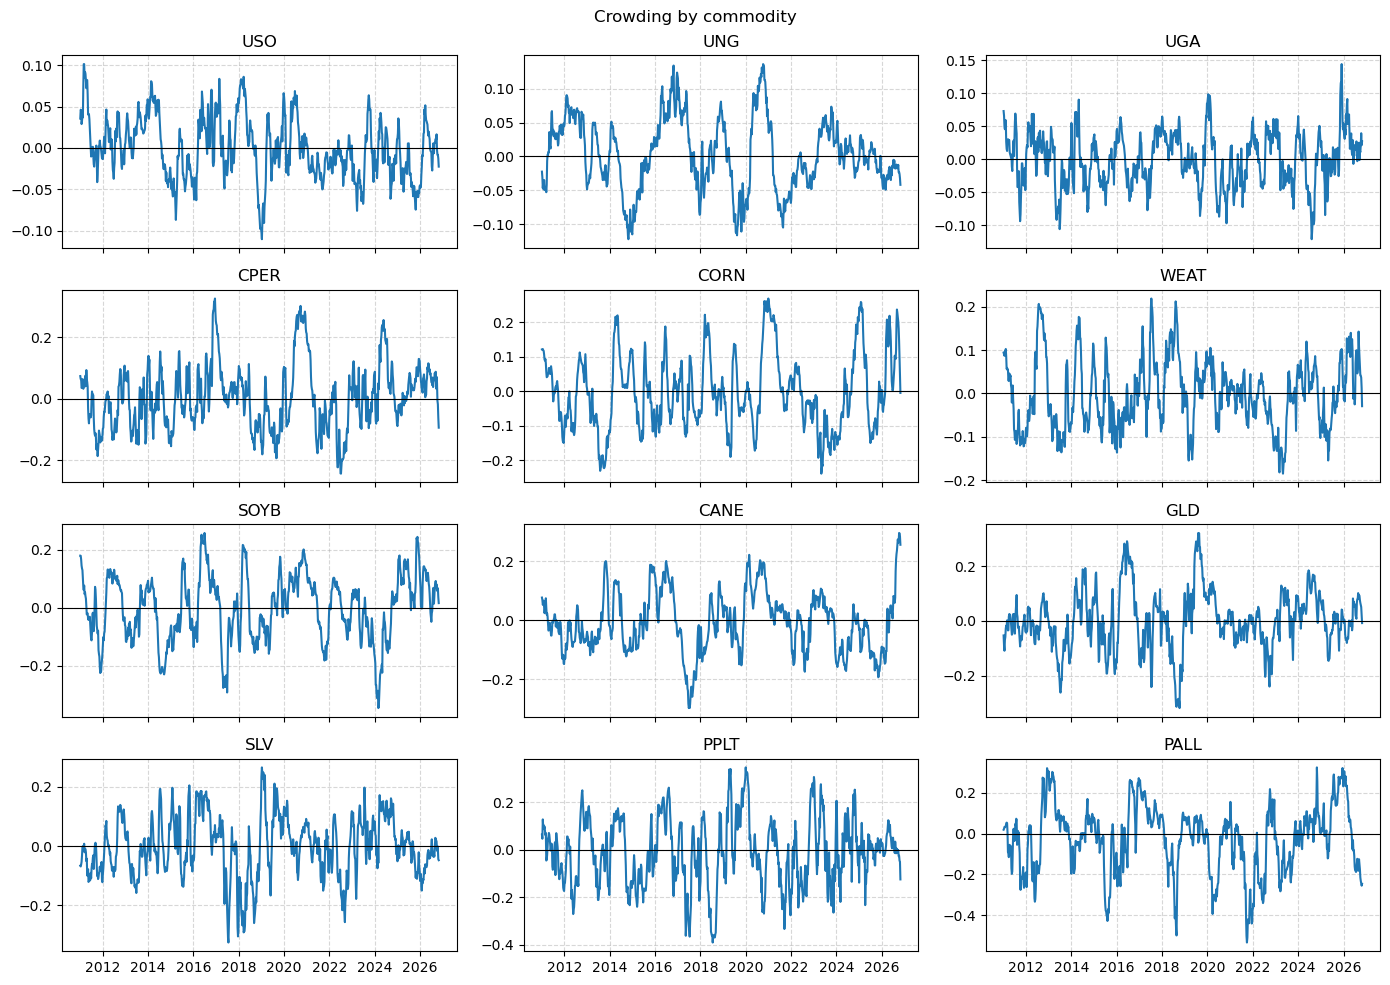

In [7]:
fig, axes = plt.subplots(4, 3, figsize=(14, 10), sharex=True)
for ax, ticker in zip(axes.flat, MARKETS):
    line(crowding[ticker], ax=ax, title=ticker, legend=False, sort=False)
    ax.axhline(0, color="black", lw=0.8)
fig.suptitle("Crowding by commodity")
fig.tight_layout()

## 2. Method

**Momentum.** Each Tuesday we rank the 12 ETFs on their past 52-week return, buy the top 6 and short the bottom 6 with equal weights, and hold for one week (the paper trades 13 against 13):

$$
MOM_{i,t} = \prod_{k=0}^{51}(1 + r_{i,t-k}) - 1,
\qquad
w_{i,t} = \begin{cases} +1/6 & \text{if } i \in L_t \text{ (top 6)} \\ -1/6 & \text{if } i \in S_t \text{ (bottom 6)} \end{cases}
\qquad
R^{MOM}_{t+1} = \sum_{i=1}^{12} w_{i,t}\, r_{i,t+1}.
$$

**Factor crowding.** Following equation (5) of the paper, we average the crowding of the constituents, with a plus sign for longs and a minus sign for shorts:

$$
C^{MOM}_t = \frac{1}{2}\left(\frac{1}{6}\sum_{i \in L_t} C_{i,t} - \frac{1}{6}\sum_{i \in S_t} C_{i,t}\right) = \frac{1}{2}\sum_{i=1}^{12} w_{i,t}\, C_{i,t}.
$$

**Crowding rule.** As in Figure 2 of the paper, the low-crowding strategy holds the momentum portfolio only when factor crowding is below its average over the previous 156 weeks, and stays in cash otherwise. The high-crowding strategy does the opposite, so the two add up to classical momentum:

$$
\bar C_t = \frac{1}{156}\sum_{k=1}^{156} C^{MOM}_{t-k},
\qquad
e_t = \mathbb{1}_{\{C^{MOM}_t < \bar C_t\}},
$$

$$
R^{LOW}_{t+1} = e_t\, R^{MOM}_{t+1},
\qquad
R^{HIGH}_{t+1} = (1 - e_t)\, R^{MOM}_{t+1}.
$$

**Scope.** As in the paper, we ask whether crowding predicts momentum returns, not whether a fund could trade on it. Positions are dated on the Tuesday they are measured, $C_{i,t}$, before the return of the following week, but the CFTC only publishes them on the Friday. Returns are before transaction costs. Our results are therefore descriptive, not an executable backtest. We come back to this point in Section 3, using only published positions.

Sharpe ratios are annualised with $\sqrt{52}$, and cumulative returns are sums of weekly returns, as in the course.

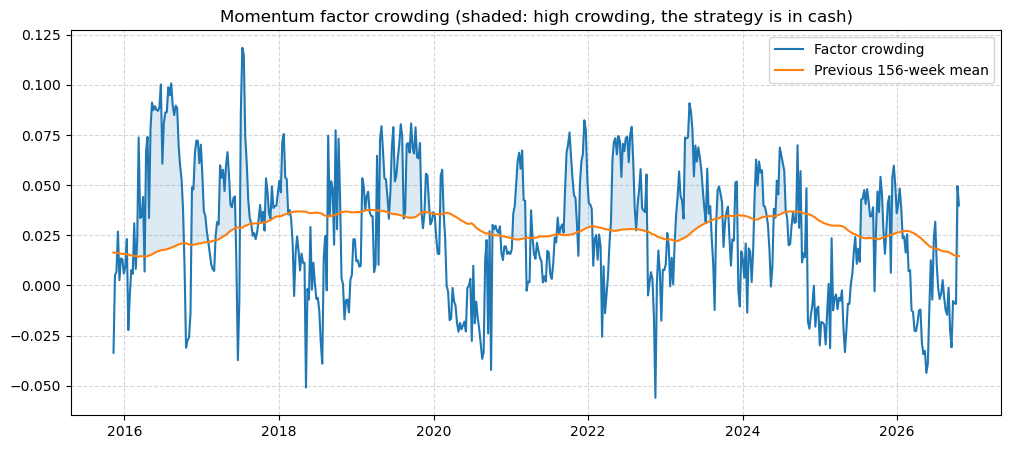

In [8]:
mom = np.log1p(ret).rolling(52).sum().dropna().iloc[:-1]  # same ranking as the 52-week return; the last week has no next-week return
rank = mom.rank(axis=1, ascending=False, method="first")
w = (rank.le(N_LEG).astype(float) - rank.gt(N_LEG).astype(float)) / N_LEG


def factor_crowding(crowding, lag=0):
    aligned = crowding.reindex(ret.index, method="ffill", tolerance=pd.Timedelta(days=6)).shift(lag)
    return 0.5 * (w * aligned.loc[w.index]).sum(axis=1)


def regime(crowding, lag=0, window=156):
    C = factor_crowding(crowding, lag)
    threshold = C.shift(1).rolling(window).mean().dropna()
    return C.loc[threshold.index], threshold, C.loc[threshold.index] < threshold


def book(crowding, lag=0):
    _, _, low = regime(crowding, lag)
    h = w.loc[low.index]
    return {
        "Classical": h,
        "Low crowding": h.mul(low.astype(float), axis=0),
        "High crowding": h.mul((~low).astype(float), axis=0),
    }


def pnl(h):
    return compute_pnl(h.reindex(ret.index), ret, 1).reindex(h.index + pd.Timedelta(weeks=1))


def report(strategies):
    return pd.DataFrame(
        {
            name: {
                "Sharpe": sr(pnl(h)),
                "return (%/yr)": pnl(h).mean() * 5200,
                "vol (%/yr)": pnl(h).std() * np.sqrt(52) * 100,
                "max drawdown (%)": drawdown(pnl(h), return_in_risk_unit=False).min() * 100,
                "weeks invested (%)": h.abs().sum(axis=1).gt(0).mean() * 100,
                "holding period (weeks)": average_holding_period(h),
            }
            for name, h in strategies.items()
        }
    ).T.round(2)


C, threshold, low = regime(crowding)
fig, ax = plt.subplots(figsize=(12, 5))
line(
    pd.DataFrame({"Factor crowding": C, "Previous 156-week mean": threshold}),
    ax=ax, sort=False, loc="best", title="Momentum factor crowding (shaded: high crowding, the strategy is in cash)",
)
ax.fill_between(C.index, C, threshold, where=~low, alpha=0.15);

## 3. Results

### Performance

In [9]:
report(book(crowding))

,Sharpe,return (%/yr),vol (%/yr),max drawdown (%),weeks invested (%),holding period (weeks)
Classical,0.25,5.06,20.52,-37.64,100.00,14.48
Low crowding,0.38,5.81,15.25,-25.58,50.87,4.62
High crowding,-0.05,-0.75,13.73,-58.57,49.13,4.62


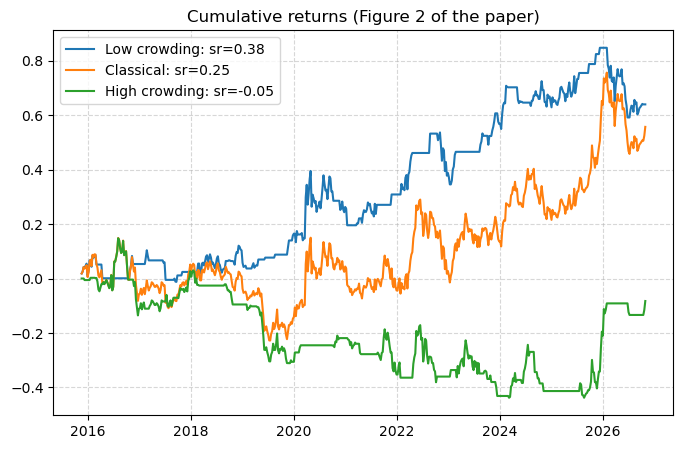

In [10]:
pnls = {k: pnl(h) for k, h in book(crowding).items()}
line({f"{k}: sr={sr(v):.2f}": v for k, v in pnls.items()}, cumsum=True, legend_sharpe_ratio=False, loc="best", title="Cumulative returns (Figure 2 of the paper)")

Classical momentum split by crowding regime (in % of return):

In [11]:
(pnl(w.loc[low.index]) * 100).groupby(np.where(low, "Low crowding", "High crowding")).agg(
    weeks="size", mean_weekly="mean", total="sum"
).round(3)

,weeks,mean_weekly,total
High crowding,281,-0.029,-8.259
Low crowding,291,0.220,63.930


### Can this be executed?

The results above follow the timing of the paper: the decision taken on Tuesday $t$ uses the positions measured on that same Tuesday, $C_{i,t}$. The paper describes the report as published on Tuesday (its Section 2). In practice, the CFTC measures positions at the close on Tuesday and releases them on Friday at 15:30 New York time. Investors therefore do not know $C_{i,t}$ on the day of the decision, and Figure 2 cannot be executed as such: it shows a link between crowding and subsequent returns, not a tradable rule.

We measure what this timing is worth by replacing $C_{i,t}$ with the latest report that is public on Tuesday $t$, the one measured a week earlier (lag 1):

$$
C^{MOM}_t = \frac{1}{2}\sum_{i=1}^{12} w_{i,t}\, C_{i,t-1}.
$$

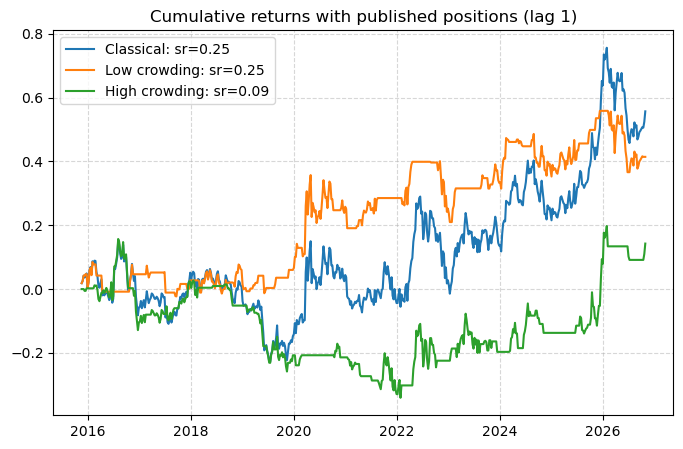

In [12]:
line({f"{k}: sr={sr(pnl(h)):.2f}": pnl(h) for k, h in book(crowding, lag=1).items()}, cumsum=True, legend_sharpe_ratio=False, loc="best", title="Cumulative returns with published positions (lag 1)")

### Reading of the results

- **Same shape as the paper.** With the paper's timing, momentum earns more after low crowding than after high crowding: 64% against -8% in cumulative returns.
- **Not executable as such.** With published positions, the gap narrows to 41% against 14%, and the low-crowding strategy has a Sharpe ratio of 0.25, the same as classical momentum. The paper documents a link between crowding and subsequent momentum returns, but with these data this link does not give an investor a better strategy than simple momentum.

## 4. Machine learning

We follow the course's walk-forward approach (`skfin.Backtester`) to predict **next-week ETF returns**. Every Tuesday, the six ETFs with the highest forecasts are bought and the other six are sold, as in Section 2. This section does not use CFTC data.

### 4.1 Data and features

The predictors use past returns, risk, trends, relative performance, trading volume, macroeconomic indicators and seasonality. As in the course, the target is simply the next-period return: $y_{i,t}=r_{i,t+1}$. We retain the existing 35 numerical features, add 24 historical features and encode ETF identity and commodity group (16 indicators).

In [13]:
from io import StringIO
from pathlib import Path

import yfinance as yf
from scipy.stats import loguniform, randint, uniform
from sklearn.base import BaseEstimator
from sklearn.model_selection import ParameterSampler
from xgboost import XGBRegressor
from skfin.backtesting import Backtester

TEST = "2023-01-01"
VALIDATION = "2020-01-01"
TRAIN_WEEKS = 260
COST_BPS = 5

out = Path(CACHE) / "xgboost"
out.mkdir(parents=True, exist_ok=True)
tickers = list(MARKETS)
groups = {
    "USO": "Energy", "UNG": "Energy", "UGA": "Energy",
    "CPER": "Industrial metal",
    "CORN": "Agriculture", "WEAT": "Agriculture", "SOYB": "Agriculture", "CANE": "Agriculture",
    "GLD": "Precious metal", "SLV": "Precious metal", "PPLT": "Precious metal", "PALL": "Precious metal",
}


def load_extra_data():
    def yahoo():
        raw = yf.download(tickers, start=START, end=END, auto_adjust=False,
                          progress=False, threads=False)
        if "Close" not in raw.columns.get_level_values(0):
            raw = raw.swaplevel(0, 1, axis=1)
        return pd.concat({
            "Close": raw["Close"].reindex(columns=tickers),
            "Volume": raw["Volume"].reindex(columns=tickers),
        }, axis=1).sort_index()

    def fred():
        series = {}
        for name in ("DTWEXBGS", "VIXCLS", "DFII10", "T10YIE", "T10Y2Y"):
            url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={name}"
            data = pd.read_csv(StringIO(WebUtils.get_response(url).text))
            series[name] = pd.Series(pd.to_numeric(data[name], errors="coerce").to_numpy(),
                                     index=pd.to_datetime(data.iloc[:, 0]))
        return pd.DataFrame(series).sort_index()

    prices = CacheManager(CACHE).get_cached_dataframe("ml_yahoo_ohlcv.parquet", yahoo)
    macro = CacheManager(CACHE).get_cached_dataframe("ml_fred_macro.parquet", fred)
    return prices, macro


prices, macro_daily = load_extra_data()
close, volume = prices["Close"], prices["Volume"]

In [14]:
log_ret = np.log1p(ret)
f = {f"Mom_{n}w": np.expm1(log_ret.rolling(n).sum()) for n in (1, 4, 13, 26)}
f["Mom_52w"] = np.expm1(mom.reindex(ret.index))
f["MomAcceleration"] = f["Mom_4w"] - np.expm1(np.log1p(f["Mom_13w"]) * 4 / 13)

for n in (4, 13, 52):
    f[f"Vol_{n}w"] = ret.rolling(n).std()
f["DownsideVol_13w"] = np.sqrt(ret.clip(upper=0).pow(2).rolling(13).mean())
f["Skew_26w"] = ret.rolling(26).skew()

nav = (1 + ret).cumprod()
f["DistanceHigh_52w"] = nav / nav.rolling(52).max() - 1
f["TrendEfficiency_13w"] = (nav - nav.shift(13)).abs() / nav.diff().abs().rolling(13).sum().replace(0, np.nan)
f["MaxDrawdown_13w"] = nav.rolling(13).apply(lambda a: (a / np.maximum.accumulate(a) - 1).min(), raw=True)
gain = ret.clip(lower=0).rolling(13).mean()
loss = -ret.clip(upper=0).rolling(13).mean()
f["RSI_13w"] = 100 * gain / (gain + loss).replace(0, np.nan)
f["Reversal_1w"] = -ret

repeat = lambda s: pd.DataFrame({k: s for k in tickers})
f["RelativeMom_13w"] = f["Mom_13w"].sub(f["Mom_13w"].mean(axis=1), axis=0)
f["MomRank_52w"] = f["Mom_52w"].rank(axis=1, ascending=False, pct=True)
f["RelativeVol_13w"] = f["Vol_13w"].div(f["Vol_13w"].median(axis=1).replace(0, np.nan), axis=0)
f["MarketMom_4w"] = repeat(f["Mom_4w"].mean(axis=1))
f["Dispersion_4w"] = repeat(f["Mom_4w"].std(axis=1))
f["SectorRelativeMom_13w"] = pd.DataFrame({
    k: f["Mom_13w"][k] - f["Mom_13w"][[j for j in tickers if groups[j] == groups[k]]].mean(axis=1)
    for k in tickers
})

dollar = close * volume
weekly_volume = volume.resample("W-TUE").sum(min_count=1).reindex(ret.index)
weekly_dollar = dollar.resample("W-TUE").sum(min_count=1).reindex(ret.index)
log_dollar = np.log1p(weekly_dollar)
f["LogDollarVolume_4w"] = log_dollar.rolling(4).mean()
f["DollarVolumeZ_13w"] = (log_dollar - log_dollar.rolling(13).mean()) / log_dollar.rolling(13).std().replace(0, np.nan)
f["VolumeChange_4w"] = weekly_volume.rolling(4).mean() / weekly_volume.shift(4).rolling(4).mean().replace(0, np.nan) - 1
f["Amihud_4w"] = (daily.abs() / (dollar.reindex(daily.index) / 1e6).replace(0, np.nan)).resample("W-TUE").mean().rolling(4).mean().reindex(ret.index)

macro = macro_daily.reindex(ret.index - pd.Timedelta(days=7), method="ffill", tolerance=pd.Timedelta(days=10))
macro.index = ret.index
macro_features = pd.DataFrame({
    "USD_4w": macro["DTWEXBGS"].pct_change(4, fill_method=None),
    "VIX": macro["VIXCLS"],
    "VIX_4w": macro["VIXCLS"].diff(4),
    "RealYield10Y": macro["DFII10"],
    "RealYield_4w": macro["DFII10"].diff(4),
    "Breakeven10Y": macro["T10YIE"],
    "YieldSlope": macro["T10Y2Y"],
})
f.update({name: repeat(macro_features[name]) for name in macro_features})
f["SeasonSin"] = repeat(pd.Series(np.sin(2 * np.pi * ret.index.dayofyear / 365.25), index=ret.index))
f["SeasonCos"] = repeat(pd.Series(np.cos(2 * np.pi * ret.index.dayofyear / 365.25), index=ret.index))

**Historical features.** For four signals, we add their standard deviation, minimum, maximum, 10th and 90th percentiles over the **preceding 26 weeks**. The z-score compares today's signal with that past distribution. The `shift(1)` prevents the current observation from entering its own historical reference window.

In [15]:
for name in ("Mom_13w", "Mom_52w", "Vol_13w", "LogDollarVolume_4w"):
    x = f[name]
    past = x.shift(1).rolling(26, min_periods=26)
    mean, std = past.mean(), past.std()
    f[f"{name}_HistStd"] = std
    f[f"{name}_HistMin"] = past.min()
    f[f"{name}_HistMax"] = past.max()
    f[f"{name}_HistQ10"] = past.quantile(.10)
    f[f"{name}_HistQ90"] = past.quantile(.90)
    f[f"{name}_HistZ"] = (x - mean) / std.replace(0, np.nan)

for ticker in tickers:
    f[f"ETF_{ticker}"] = pd.DataFrame({k: float(k == ticker) for k in tickers}, index=ret.index)
for group in sorted(set(groups.values())):
    f[f"Group_{group}"] = pd.DataFrame({k: float(groups[k] == group) for k in tickers}, index=ret.index)

target = ret.shift(-1).reindex(w.index).dropna()
features = pd.concat({
    ticker: pd.DataFrame({name: values[ticker] for name, values in f.items()})
    for ticker in tickers
}, axis=1).reindex(target.index).replace([np.inf, -np.inf], np.nan)

assert features.shape[1] == len(tickers) * len(f)
assert target.columns.tolist() == tickers
assert target.notna().all().all()
print(f"{len(features)} weekly observations, {len(tickers)} ETFs, {len(f)} features per ETF")

728 weekly observations, 12 ETFs, 75 features per ETF


### 4.2 Model and hyperparameters


In [16]:
class RankXGB(BaseEstimator):
    def __init__(self, params=None):
        self.params = params

    def fit(self, X, y):
        self.n_assets_ = y.shape[1]
        self.n_features_ = X.shape[1] // self.n_assets_
        self.model_ = XGBRegressor(objective="reg:squarederror", tree_method="hist",
                                   random_state=42, n_jobs=1, **(self.params or {}))
        self.model_.fit(X.reshape(-1, self.n_features_), y.reshape(-1))
        return self

    def forecast(self, X):
        return self.model_.predict(X.reshape(-1, self.n_features_)).reshape(-1, self.n_assets_)

    def predict(self, X):
        forecast = self.forecast(X)
        rank = pd.DataFrame(forecast).rank(axis=1, ascending=False, method="first")
        return np.where(rank <= N_LEG, 1 / N_LEG, -1 / N_LEG)

In [17]:
param_distributions = {
    "max_depth": randint(1, 5),
    "n_estimators": randint(60, 301),
    "learning_rate": loguniform(.01, .15),
    "min_child_weight": randint(2, 41),
    "subsample": uniform(.7, .3),
    "colsample_bytree": uniform(.7, .3),
    "reg_alpha": loguniform(1e-5, .1),
    "reg_lambda": loguniform(.01, 100),
    "gamma": uniform(0, .005),
}

cache_file = out / "parameter_search.csv"
force_recompute = False
if cache_file.exists() and not force_recompute:
    results = pd.read_csv(cache_file)
else:
    scores = []
    for params in ParameterSampler(param_distributions, n_iter=24, random_state=42):
        estimator = RankXGB(params)
        backtest = Backtester(estimator, max_train_size=TRAIN_WEEKS, test_size=4,
                              start_date=VALIDATION, end_date="2022-12-27")
        returns = backtest.train(features, target, ret)
        scores.append({**params, "Sharpe": sr(returns)})
    results = pd.DataFrame(scores).sort_values("Sharpe", ascending=False)
    results.to_csv(cache_file, index=False)

results = results.sort_values("Sharpe", ascending=False)
best_params = results.iloc[0].drop("Sharpe").to_dict()
for name in ("max_depth", "n_estimators", "min_child_weight"):
    best_params[name] = int(best_params[name])
print("Selected parameters:", best_params)
display(results.head(10).round(4))

Selected parameters: {'colsample_bytree': 0.8281323365878769, 'gamma': 0.004090073829612466, 'learning_rate': 0.10287212602939473, 'max_depth': 3, 'min_child_weight': 7, 'n_estimators': 259, 'reg_alpha': 0.0013688557276310292, 'reg_lambda': 0.8696007095406233, 'subsample': 0.9077308098670811}


,colsample_bytree,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_alpha,reg_lambda,subsample,Sharpe
16,0.8281,0.0041,0.1029,3,7,259,0.0014,0.8696,0.9077,0.8597
15,0.9411,0.0009,0.1121,3,29,276,0.0002,0.0276,0.7684,0.7705
6,0.8640,0.0009,0.1381,2,35,261,0.0380,2.4638,0.9766,0.7321
0,0.8124,0.0048,0.0726,1,22,162,0.0006,0.0251,0.8378,0.6229
23,0.9513,0.0034,0.0732,2,24,218,0.0323,0.1076,0.8980,0.5321
21,0.8607,0.0005,0.0960,4,7,267,0.0000,2.3098,0.9033,0.5213
22,0.7050,0.0026,0.0185,4,8,111,0.0578,0.3893,0.8553,0.4143
14,0.9829,0.0030,0.0656,4,3,229,0.0171,3.4168,0.9614,0.3549
13,0.8909,0.0016,0.0396,2,38,210,0.0026,1.4433,0.7609,0.3057
9,0.7596,0.0000,0.0910,1,9,222,0.0145,2.6536,0.9779,0.1954


### 4.3 Out-of-sample backtest (2023–2026)

Following the course, `Backtester` uses `TimeSeriesSplit` and trains a **new model each week** (`test_size=1`). At date $t$, it only fits on past observations; holdings based on the signal at $t$ earn the return over $t$ to $t+1$ (`pred_lag=1`). We compare the same 6/6 portfolio against classical momentum on identical weeks.

In [18]:
estimator = RankXGB(best_params)
backtest = Backtester(estimator, max_train_size=TRAIN_WEEKS, test_size=1,
                      pred_lag=1, start_date=TEST)
backtest.train(features, target, ret)

h = backtest.h_.loc[TEST:, tickers]
strategies = {"Classical": w.loc[h.index], "XGBoost": h}
report(strategies)

,Sharpe,return (%/yr),vol (%/yr),max drawdown (%),weeks invested (%),holding period (weeks)
Classical,0.68,14.23,21.05,-29.83,100.0,13.88
XGBoost,0.49,8.57,17.34,-30.54,100.0,2.33


,Gross Sharpe,Net Sharpe
Classical,0.676,0.639
XGBoost,0.495,0.236


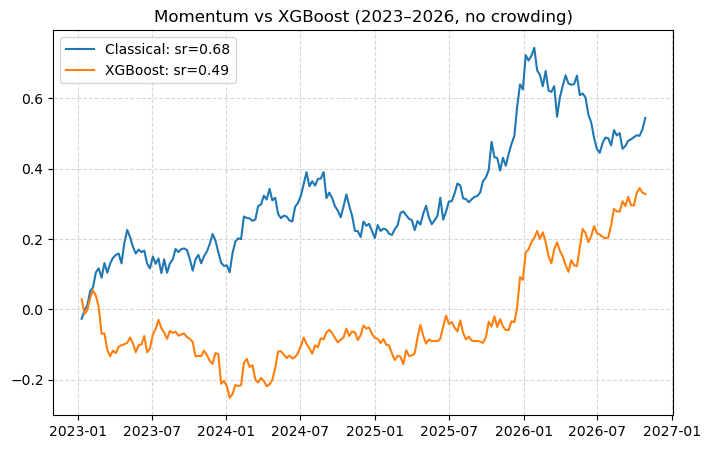

In [19]:
pnls_ml = {name: pnl(positions) for name, positions in strategies.items()}
line({f"{name}: sr={sr(value):.2f}": value for name, value in pnls_ml.items()},
     cumsum=True, legend_sharpe_ratio=False, loc="best",
     title="Momentum vs XGBoost (2023–2026, no crowding)")

pnls_net = {}
for name, positions in strategies.items():
    turnover = positions.diff().fillna(positions).abs().sum(axis=1)
    turnover.index = turnover.index + pd.Timedelta(weeks=1)
    pnls_net[name] = pnls_ml[name] - COST_BPS / 10000 * turnover.reindex(pnls_ml[name].index).fillna(0)

pd.DataFrame({name: {"Gross Sharpe": sr(pnls_ml[name]),
                     "Net Sharpe": sr(pnls_net[name])}
              for name in strategies}).T.round(3)

### 4.4 Forecast accuracy and data checks

The model predicts next-week **absolute** returns. We report out-of-sample RMSE and average weekly cross-sectional Spearman Rank IC, alongside the Sharpe. These are diagnostics, not additional criteria for selecting the hyperparameters.

OOS RMSE: 4.65%
OOS Rank IC: 0.0290
ETFs included each week: 12
Missing price observations since 2023:


Ticker
USO     0.0
UNG     0.0
UGA     0.0
CPER    0.0
CORN    0.0
WEAT    0.0
SOYB    0.0
CANE    0.0
GLD     0.0
SLV     0.0
PPLT    0.0
PALL    0.0
dtype: float64

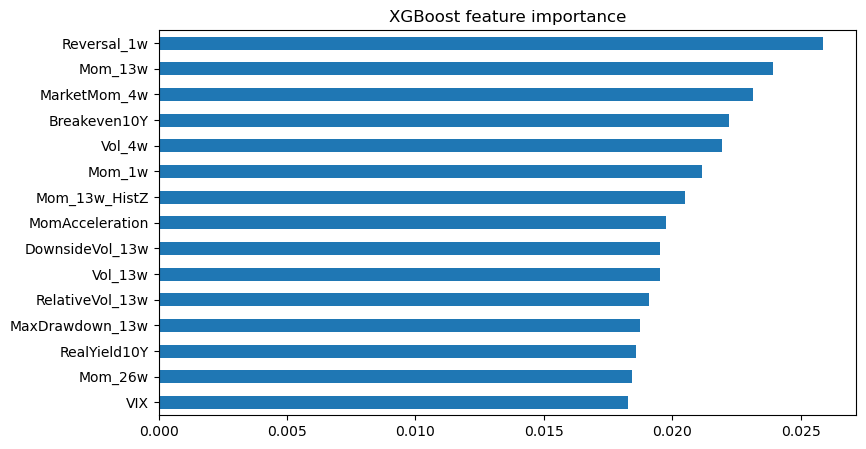

In [20]:
forecast = pd.DataFrame(
    np.vstack([model.forecast(features.loc[[date]].to_numpy())
               for date, model in zip(backtest.h_.index, backtest.estimators_)]),
    index=backtest.h_.index, columns=tickers,
).loc[h.index]
actual = target.loc[h.index]
rmse = np.sqrt(((forecast - actual) ** 2).stack().mean())
rank_ic = forecast.corrwith(actual, axis=1, method="spearman").mean()

print(f"OOS RMSE: {rmse:.2%}")
print(f"OOS Rank IC: {rank_ic:.4f}")
print("ETFs included each week:", h.notna().sum(axis=1).min())
print("Missing price observations since 2023:")
display(close.loc[TEST:].isna().mean().mul(100).round(2))

importance = pd.concat([
    pd.Series(model.model_.feature_importances_, index=features[tickers[0]].columns)
    for model in backtest.estimators_
], axis=1).mean(axis=1).sort_values(ascending=False)
importance.head(15).sort_values().plot.barh(figsize=(9, 5), title="XGBoost feature importance");